# Case Study 2: Cloud Identity, Authentication & Authorization
### Local demonstration notebook | JWT validation · Default-deny policy evaluation

**Purpose.** Demonstrate the two simplified programs described in the case study report. The first validates a signed JSON Web Token (JWT) and checks required claims. The second evaluates access requests using explicit deny, guardrails, explicit allow, and implicit deny.

**Important scope note:** this is a local simulation. It generates its own test keys and uses sample identities/resources. It does not connect to a real identity provider, cloud IAM service, production API, or cloud account. Google Colab is just the notebook runtime.

**How to run:** select **Runtime → Run all**. The test tables show expected versus actual outcomes, making the security logic straightforward to demonstrate.

## 1. Setup
We use Python's `cryptography` library to create an ephemeral RSA key pair and verify RS256 signatures. The private key is generated for this notebook session only; it is not a real identity-provider key.

In [1]:
%pip -q install cryptography

Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64
import json
import time
import pandas as pd
from cryptography.hazmat.primitives.asymmetric import rsa, padding
from cryptography.hazmat.primitives import hashes

print("Setup complete. Pandas:", pd.__version__)

def b64url_encode(data: bytes) -> str:
    return base64.urlsafe_b64encode(data).rstrip(b'=').decode('ascii')

def b64url_decode(text: str) -> bytes:
    return base64.urlsafe_b64decode(text + '=' * (-len(text) % 4))

private_key = rsa.generate_private_key(public_exponent=65537, key_size=2048)
public_key = private_key.public_key()
other_private_key = rsa.generate_private_key(public_exponent=65537, key_size=2048)
ISSUER = 'https://idp.example.com'
AUDIENCE = 'api://orders'
ALLOWED_ALGORITHMS = {'RS256'}
KEYS = {'key-01': public_key}
print("Ephemeral RSA keys created; only RS256 is allowed in this demo.")

Setup complete. Pandas: 2.2.3


Ephemeral RSA keys created; only RS256 is allowed in this demo.


## 2. Authentication and token validation
A JWT signature alone is not enough. The validator checks token structure, the permitted algorithm, known key ID, signature, issuer, audience, expiry, and required scope. Invalid or malformed tokens should be rejected.

In [3]:
def make_token(payload, algorithm='RS256', signing_key=None, key_id='key-01'):
    signing_key = signing_key or private_key
    header = {'alg': algorithm, 'typ': 'JWT', 'kid': key_id}
    h = b64url_encode(json.dumps(header, separators=(',', ':')).encode())
    p = b64url_encode(json.dumps(payload, separators=(',', ':')).encode())
    signing_input = f'{h}.{p}'.encode()
    if algorithm == 'none':
        signature = b''
    elif algorithm == 'RS256':
        signature = signing_key.sign(signing_input, padding.PKCS1v15(), hashes.SHA256())
    else:
        signature = b'demo-unsupported-algorithm'
    return f'{h}.{p}.{b64url_encode(signature)}'

def validate_token(token, now=None, required_scope='orders.read'):
    now = time.time() if now is None else now
    try:
        parts = token.split('.')
        if len(parts) != 3:
            return False, 'malformed token'
        h, p, s = parts
        header = json.loads(b64url_decode(h))
        payload = json.loads(b64url_decode(p))
        if not isinstance(header, dict) or not isinstance(payload, dict):
            return False, 'invalid JSON object'
    except (ValueError, TypeError, json.JSONDecodeError, UnicodeDecodeError):
        return False, 'malformed header or payload'
    except Exception:
        return False, 'malformed token encoding'

    if header.get('alg') not in ALLOWED_ALGORITHMS:
        return False, 'algorithm not allowed'
    key = KEYS.get(header.get('kid'))
    if key is None:
        return False, 'unknown key id'
    try:
        key.verify(b64url_decode(s), f'{h}.{p}'.encode(), padding.PKCS1v15(), hashes.SHA256())
    except Exception:
        return False, 'bad signature'
    if payload.get('iss') != ISSUER:
        return False, 'wrong issuer'
    audience = payload.get('aud')
    audience = audience if isinstance(audience, list) else [audience]
    if AUDIENCE not in audience:
        return False, 'wrong audience'
    if not isinstance(payload.get('exp'), (int, float)) or now >= payload['exp']:
        return False, 'expired or missing expiry'
    if required_scope not in str(payload.get('scope', '')).split():
        return False, 'missing scope'
    return True, 'ok'

now = time.time()
base_claims = {'iss': ISSUER, 'sub': 'user-1042', 'aud': AUDIENCE,
               'scope': 'orders.read', 'exp': now + 300}
valid_token = make_token(base_claims)
print("Example token generated (not printed in full to avoid clutter).")
print("Validation result:", validate_token(valid_token))

Example token generated (not printed in full to avoid clutter).
Validation result: (True, 'ok')


In [4]:
token_tests = [
    ('Valid token', valid_token, True),
    ('Expired token', make_token({**base_claims, 'exp': now-10}), False),
    ('Wrong audience', make_token({**base_claims, 'aud': 'api://billing'}), False),
    ('Wrong issuer', make_token({**base_claims, 'iss': 'https://evil.example'}), False),
    ('Missing required scope', make_token({**base_claims, 'scope': 'orders.write'}), False),
    ('alg = none', make_token(base_claims, algorithm='none'), False),
    ('Signed by another key', make_token(base_claims, signing_key=other_private_key), False),
]
# Modify the payload without re-signing it: signature verification must fail.
parts = valid_token.split('.')
tampered_payload = {**base_claims, 'sub': 'admin'}
parts[1] = b64url_encode(json.dumps(tampered_payload, separators=(',', ':')).encode())
token_tests.append(('Tampered payload', '.'.join(parts), False))

token_results = []
for name, token, expected_accept in token_tests:
    accepted, reason = validate_token(token)
    token_results.append({'Test case': name, 'Expected': 'Accept' if expected_accept else 'Reject',
                          'Actual': 'Accept' if accepted else 'Reject', 'Reason': reason,
                          'Result': 'PASS' if accepted == expected_accept else 'FAIL'})
token_df = pd.DataFrame(token_results)
display(token_df)
assert (token_df['Result'] == 'PASS').all(), 'At least one JWT test did not meet its expected result.'
print(f"Passed {sum(token_df['Result']=='PASS')} of {len(token_df)} token tests.")

,Test case,Expected,Actual,Reason,Result
0,Valid token,Accept,Accept,ok,PASS
1,Expired token,Reject,Reject,expired or missing expiry,PASS
2,Wrong audience,Reject,Reject,wrong audience,PASS
3,Wrong issuer,Reject,Reject,wrong issuer,PASS
4,Missing required scope,Reject,Reject,missing scope,PASS
5,alg = none,Reject,Reject,algorithm not allowed,PASS
6,Signed by another key,Reject,Reject,bad signature,PASS
7,Tampered payload,Reject,Reject,bad signature,PASS


Passed 8 of 8 token tests.


### What the JWT tests demonstrate
- **Issuer and audience:** the token must be intended for the expected identity provider and API.
- **Expiry and scope:** a valid signature does not override token lifetime or permissions.
- **Algorithm/key/signature checks:** reject `alg=none`, unknown keys, invalid signatures, and payload tampering.

This is a compact educational validator, not a drop-in production JWT library. Production systems should use a maintained standards-compliant library and handle key rotation, clock skew, revocation/session policy, and provider metadata appropriately.

## 3. Authorization: default-deny policy evaluator

Authentication answers **who/what is presenting the request?** Authorization answers **is that identity allowed to perform this action on this resource under the current context?** This demonstration follows the report's simplified policy rules:

1. A matching explicit `Deny` takes precedence.
2. A request outside the resource guardrail is denied.
3. A matching explicit `Allow` is permitted.
4. Anything else is denied by default (implicit deny).

In [5]:
policies = [
    {'effect': 'Allow', 'actions': {'s3:GetObject'}, 'resource': 'reports/', 'conditions': {'mfa': True}},
    {'effect': 'Allow', 'actions': {'deploy'}, 'resource': 'acct-test', 'conditions': {}},
    {'effect': 'Deny', 'actions': {'db:Delete'}, 'resource': '*', 'conditions': {}},
]

def in_guardrail(request):
    root = request['resource'].split('/')[0]
    return root in {'reports', 'acct-test', 'prod-db', 'acct-prod'}

def evaluate_request(request, policy_set=policies, guardrail=in_guardrail):
    matches = []
    for policy in policy_set:
        resource_matches = policy['resource'] == '*' or request['resource'].startswith(policy['resource'])
        conditions_match = all(request.get('context', {}).get(k) == v
                               for k, v in policy.get('conditions', {}).items())
        if request['action'] in policy['actions'] and resource_matches and conditions_match:
            matches.append(policy)
    if any(p['effect'] == 'Deny' for p in matches):
        return 'DENY', 'explicit deny'
    if not guardrail(request):
        return 'DENY', 'outside guardrail'
    if any(p['effect'] == 'Allow' for p in matches):
        return 'ALLOW', 'explicit allow'
    return 'DENY', 'implicit deny'

requests = [
    ('Analyst reads report, MFA', {'action':'s3:GetObject', 'resource':'reports/q3.csv', 'context':{'mfa':True}}, 'ALLOW'),
    ('Analyst reads report, no MFA', {'action':'s3:GetObject', 'resource':'reports/q3.csv', 'context':{'mfa':False}}, 'DENY'),
    ('Developer deletes production DB', {'action':'db:Delete', 'resource':'prod-db', 'context':{}}, 'DENY'),
    ('Pipeline deploys to test account', {'action':'deploy', 'resource':'acct-test', 'context':{}}, 'ALLOW'),
    ('Pipeline deploys to production', {'action':'deploy', 'resource':'acct-prod', 'context':{}}, 'DENY'),
    ('Request to unlisted service', {'action':'s3:GetObject', 'resource':'hr-data/x', 'context':{'mfa':True}}, 'DENY'),
]
policy_rows = []
for label, request, expected in requests:
    decision, reason = evaluate_request(request)
    policy_rows.append({'Request':label, 'Expected':expected, 'Actual':decision,
                        'Reason':reason, 'Result':'PASS' if decision == expected else 'FAIL'})
policy_df = pd.DataFrame(policy_rows)
display(policy_df)
assert (policy_df['Result'] == 'PASS').all(), 'At least one policy test did not meet its expected result.'
print(f"Passed {sum(policy_df['Result']=='PASS')} of {len(policy_df)} authorization tests.")

,Request,Expected,Actual,Reason,Result
0,"Analyst reads report, MFA",ALLOW,ALLOW,explicit allow,PASS
1,"Analyst reads report, no MFA",DENY,DENY,implicit deny,PASS
2,Developer deletes production DB,DENY,DENY,explicit deny,PASS
3,Pipeline deploys to test account,ALLOW,ALLOW,explicit allow,PASS
4,Pipeline deploys to production,DENY,DENY,implicit deny,PASS
5,Request to unlisted service,DENY,DENY,outside guardrail,PASS


Passed 6 of 6 authorization tests.


,Control,Tests,Passed,Failed
0,JWT validation,8,8,0
1,Authorization policy,6,6,0


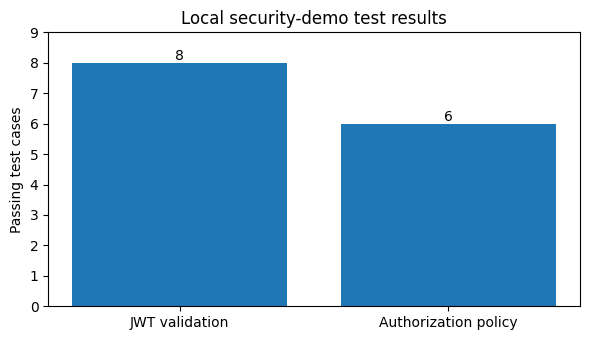

In [6]:
summary = pd.DataFrame([
    {'Control': 'JWT validation', 'Tests': len(token_df), 'Passed': int((token_df['Result']=='PASS').sum()),
     'Failed': int((token_df['Result']=='FAIL').sum())},
    {'Control': 'Authorization policy', 'Tests': len(policy_df), 'Passed': int((policy_df['Result']=='PASS').sum()),
     'Failed': int((policy_df['Result']=='FAIL').sum())},
])
display(summary)

plt = None
try:
    import matplotlib.pyplot as plt
    totals = [summary.loc[0, 'Passed'], summary.loc[1, 'Passed']]
    labels = ['JWT validation', 'Authorization policy']
    plt.figure(figsize=(6, 3.5))
    plt.bar(labels, totals)
    plt.ylim(0, max(summary['Tests']) + 1)
    plt.ylabel('Passing test cases')
    plt.title('Local security-demo test results')
    for i, value in enumerate(totals):
        plt.text(i, value + 0.1, str(value), ha='center')
    plt.tight_layout(); plt.show()
except ImportError:
    print('Matplotlib is unavailable; tables above contain the test results.')

## 4. Conclusion and presentation points

The notebook demonstrates two key ideas from the report: (1) token authentication must validate more than just a token's presence, and (2) authorization should follow least privilege with explicit deny and default-deny behavior. All test cases are checked against expected outcomes automatically.

**Scope boundary:** the test results are from a simplified local implementation using generated keys and sample policies. They do not show that AWS IAM, Microsoft Entra ID, Google Cloud IAM, or a real identity provider was configured or tested. The cloud-service mappings and reference architecture remain part of the written case study.

## Presentation checklist
1. Explain authentication versus authorization.
2. Run the JWT table and describe two or three rejected-token cases.
3. Run the policy table and explain why MFA is required for the report and why unlisted requests are denied.
4. Point out that default-deny means no matching allow policy results in a denial.
5. State that this is a local demonstration of the concepts, not a deployment to cloud IAM.